In [1]:
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
from pathlib import Path

In [2]:
path_dir_data = Path("/home/athira/CF/PhD/Data")
# path_dir_dataset  = path_dir_data / "FW_Darkness_Bonsai_08082026" 
path_dir_dataset  = path_dir_data / "LocalSearch_OptoCL" 


In [3]:
from behavior_fw.core.dataset import create_experiments_metadata, select_exp_condition

df_metadata = create_experiments_metadata(path_dir_dataset)
df_metadata

,folder_name,folder_path,date,time,datetime,genotype,protocol,medium
0,20260814_165206_Gr43a_OptoCL_ATR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260814,165206,2026-08-14 16:52:06,Gr43a,OptoCL,ATR
1,20260814_171722_Gr43a_OptoCLReplay_ATR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260814,171722,2026-08-14 17:17:22,Gr43a,OptoCLReplay,ATR
2,20260815_095930_Gr43a_OptoCL_ATR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260815,095930,2026-08-15 09:59:30,Gr43a,OptoCL,ATR
3,20260815_102821_Gr43a_OptoCLReplay_ATR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260815,102821,2026-08-15 10:28:21,Gr43a,OptoCLReplay,ATR
4,20260815_110148_Gr43a_OptoCL_NR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260815,110148,2026-08-15 11:01:48,Gr43a,OptoCL,NR
...,...,...,...,...,...,...,...,...
116,20260927_214323_Gr5a_OptoCL_ATR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260927,214323,2026-09-27 21:43:23,Gr5a,OptoCL,ATR
117,20260927_220910_Gr5a_OptoCL_NR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260927,220910,2026-09-27 22:09:10,Gr5a,OptoCL,NR
118,20260927_223457_Gr5a_OptoCL_NR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260927,223457,2026-09-27 22:34:57,Gr5a,OptoCL,NR
119,20260927_225846_Gr5a_OptoCL_NR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260927,225846,2026-09-27 22:58:46,Gr5a,OptoCL,NR


In [9]:
df_Gr43a_ATR_CL = select_exp_condition(df_metadata, genotype="Gr43a", protocol="OptoCL", medium="ATR")
df_Gr43a_ATR_CL

,folder_name,folder_path,date,time,datetime,genotype,protocol,medium
0,20260814_165206_Gr43a_OptoCL_ATR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260814,165206,2026-08-14 16:52:06,Gr43a,OptoCL,ATR
2,20260815_095930_Gr43a_OptoCL_ATR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260815,095930,2026-08-15 09:59:30,Gr43a,OptoCL,ATR
5,20260815_113758_Gr43a_OptoCL_ATR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260815,113758,2026-08-15 11:37:58,Gr43a,OptoCL,ATR
8,20260815_125712_Gr43a_OptoCL_ATR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260815,125712,2026-08-15 12:57:12,Gr43a,OptoCL,ATR
11,20260815_143303_Gr43a_OptoCL_ATR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260815,143303,2026-08-15 14:33:03,Gr43a,OptoCL,ATR
14,20260815_155106_Gr43a_OptoCL_ATR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260815,155106,2026-08-15 15:51:06,Gr43a,OptoCL,ATR
17,20260815_171245_Gr43a_OptoCL_ATR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260815,171245,2026-08-15 17:12:45,Gr43a,OptoCL,ATR
20,20260815_185656_Gr43a_OptoCL_ATR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260815,185656,2026-08-15 18:56:56,Gr43a,OptoCL,ATR
21,20260815_192251_Gr43a_OptoCL_ATR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260815,192251,2026-08-15 19:22:51,Gr43a,OptoCL,ATR
22,20260815_194752_Gr43a_OptoCL_ATR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260815,194752,2026-08-15 19:47:52,Gr43a,OptoCL,ATR


In [10]:
from behavior_fw.io.read_rawtracking import get_data_tracking
from behavior_fw.io.read_metaprotocol import get_protocol_params
from behavior_fw.io.read_stimulusLED import load_and_parse_led_stimulus

dataset = []

 
for i, (ind, row) in enumerate(df_Gr43a_ATR_CL.iterrows()):
    uid = f'{row["date"]}_{row["time"]}'
    try:
        fpath_track = Path(row["folder_path"]) / "RawTracking.csv"
        df_track = get_data_tracking(fpath_track)
        fpath_protocol = Path(row["folder_path"]) / "ProtocolMeta.csv"
        df_protocol = get_protocol_params(fpath_protocol)
        fpath_stim = Path(row["folder_path"]) / "stimulusLED.csv"

        # Replay didnt have column names for the stimulus file !
        df_stim = pd.read_csv(fpath_stim)
        

        df_stim, df_blocks = load_and_parse_led_stimulus(fpath_stim)

        df_merged = pd.merge(df_track,
                            df_stim[["LowResFrameNumber", "LEDstate"]],
                            on="LowResFrameNumber",
                            how="left")
        df_merged["LEDstate"] = df_merged["LEDstate"].fillna(0).astype(int)
        num_encounters = len(df_blocks)

        if num_encounters > 0:
            first_block = df_blocks.iloc[0]

            # Find the corresponding row index/time in your tracking DataFrame
            first_encounter_row = df_merged[
                df_merged["LowResFrameNumber"] == first_block["onset_timetick"]
            ]

            first_frame_idx = first_encounter_row.index[0]
            

            last_block = df_blocks.iloc[-1]

            last_encounter_id = last_block["encounter_id"]
            last_onset_timetick = last_block["onset_timetick"]
            last_offset_timetick = last_block.get("offset_timetick", None)

            # Find corresponding row in the merged tracking DataFrame
            last_onset_row = df_merged[
                df_merged["LowResFrameNumber"] == last_block["onset_timetick"]
            ].index[0]

            if last_offset_timetick is not None:
                last_offset_row = df_merged[
                    df_merged["LowResFrameNumber"] == last_offset_timetick
                ].index[0]
            
        else:
            first_frame_idx = None
            
        dataset.append({"uid":uid,
                        "traj_X": df_track["X"],
                        "traj_Y": df_track["Y"],
                        "zone_X": df_protocol["ZoneCenterX_mm"],
                        "zone_Y": df_protocol["ZoneCenterY_mm"],
                        "zone_r": df_protocol["ZoneRadius_mm"],
                        "n_rewards" : num_encounters,
                        "first_reward_idx": first_frame_idx,
                        "last_reward_idx": last_offset_row})
    except KeyError as e:
        print(i, uid, e)


In [16]:
from pathlib import Path
import pandas as pd
from behavior_fw.io.read_metaprotocol import get_protocol_params
from behavior_fw.io.read_rawtracking import get_data_tracking
from behavior_fw.io.read_stimulusLED import load_and_parse_led_stimulus

dataset = []

for i, (ind, row) in enumerate(df_Gr43a_ATR_CL.iterrows()):
    uid = f'{row["date"]}_{row["time"]}'
    try:
        fpath_track = Path(row["folder_path"]) / "RawTracking.csv"
        df_track = get_data_tracking(fpath_track)
        fpath_protocol = Path(row["folder_path"]) / "ProtocolMeta.csv"
        df_protocol = get_protocol_params(fpath_protocol)
        fpath_stim = Path(row["folder_path"]) / "stimulusLED.csv"
        df_stim, df_blocks = load_and_parse_led_stimulus(fpath_stim)

        df_merged = pd.merge(
            df_track,
            df_stim[["LowResFrameNumber", "LEDstate"]],
            on="LowResFrameNumber",
            how="left",
        )
        df_merged["LEDstate"] = df_merged["LEDstate"].fillna(0).astype(int)
        num_encounters = len(df_blocks)

        if num_encounters > 0:
            first_block = df_blocks.iloc[0]
            first_encounter_row = df_merged[
                df_merged["LowResFrameNumber"] == first_block["onset_timetick"]
            ]
            first_frame_idx = first_encounter_row.index[0]

            last_block = df_blocks.iloc[-1]
            last_offset_timetick = last_block.get("offset_timetick", None)

            if last_offset_timetick is not None:
                last_offset_row = df_merged[
                    df_merged["LowResFrameNumber"] == last_offset_timetick
                ].index[0]
            else:
                last_offset_row = None
        else:
            first_frame_idx = None
            last_offset_row = None  # Prevents UnboundLocalError when n_rewards == 0

        dataset.append(
            {
                "file_index": i,
                "uid": uid,
                "df_track": df_merged,
                "zone_X": df_protocol["ZoneCenterX_mm"],
                "zone_Y": df_protocol["ZoneCenterY_mm"],
                "zone_r": df_protocol["ZoneRadius_mm"],
                "n_rewards": num_encounters,
                "first_reward_idx": first_frame_idx,
                "last_reward_idx": last_offset_row,
            }
        )

    except KeyError:
        print(f"Skipped incompatible file structure at index {i}: {uid}")

In [ ]:
import matplotlib.pyplot as plt
from behavior_fw.visualization.plot_density import (
    plot_dynamic_cartesian_densities,
    plot_dynamic_polar_densities,
)


for exp in dataset:
    df_fly = exp["df_track"]
    f_idx = exp["first_reward_idx"]
    l_idx = exp["last_reward_idx"]

    # Slice into Baseline, Active Reward, and Extinction Epochs
    if f_idx is not None and l_idx is not None:
        epochs_dict = {
            "Baseline": df_fly.iloc[:f_idx].copy(),
            "Active_Reward": df_fly.iloc[f_idx:l_idx].copy(),
            "Extinction": df_fly.iloc[l_idx:].copy(),
        }
    else:
        epochs_dict = {
            "Baseline": df_fly.copy(),
            "Active_Reward": None,
            "Extinction": None,
        }

    reward_zone = {
        "x_mm": exp["zone_X"],
        "y_mm": exp["zone_Y"],
        "radius_mm": exp["zone_r"],
    }

    # 1. Plot Polar Density
    fig_polar, axes_polar = plot_dynamic_polar_densities(
        epochs_dict=epochs_dict,
        arena_r=45.0,
        title_prefix=exp["uid"],
        x_col="X",
        y_col="Y",
        reward_zone=reward_zone,
    )
    plt.show()

    # 2. Plot Cartesian Density
    fig_cart, axes_cart = plot_dynamic_cartesian_densities(
        epochs_dict=epochs_dict,
        arena_r=45.0,
        title_prefix=exp["uid"],
        x_col="X",
        y_col="Y",
        reward_zone=reward_zone,
    )
    plt.show()

In [12]:
import matplotlib.pyplot as plt
from behavior_fw.analysis.calc_velocities import get_velocities

for exp in dataset:
    # 1. Run legacy velocity calculation and LOWESS smoothing on full trajectory
    df_track_kinematics = get_velocities(exp["df_track"], fps=60.0)

    f_idx = exp["first_reward_idx"]
    l_idx = exp["last_reward_idx"]

    # 2. Slice smoothed kinematics into Baseline, Active Reward, Extinction
    if f_idx is not None and l_idx is not None:
        epochs_dict = {
            "Baseline": df_track_kinematics.iloc[:f_idx].copy(),
            "Active_Reward": df_track_kinematics.iloc[f_idx:l_idx].copy(),
            "Extinction": df_track_kinematics.iloc[l_idx:].copy(),
        }
    else:
        epochs_dict = {
            "Baseline": df_track_kinematics.copy(),
            "Active_Reward": None,
            "Extinction": None,
        }

    # Access cleaned speeds per epoch easily
    for epoch_name, df_epoch in epochs_dict.items():
        if df_epoch is not None:
            mean_vf = df_epoch["Vf_smooth"].mean()
            mean_vr = df_epoch["Vr_smooth"].abs().mean()
            print(
                f"[{exp['uid']}] {epoch_name} -> Forward Speed: {mean_vf:.2f} mm/s, Turning Speed: {mean_vr:.2f} deg/s"
            )

KeyboardInterrupt: 

In [13]:
from tqdm import tqdm

dataset = []

for i, (ind, row) in tqdm(enumerate(df_Gr43a_ATR_CL.iterrows())):
    uid = f'{row["date"]}_{row["time"]}'
    folder_path = Path(row["folder_path"])

    # Path for pre-computed kinematics file
    processed_track_path = folder_path / "ProcessedTracking.csv"

    try:
        # 1. Load or compute tracking + kinematics
        if processed_track_path.exists():
            # Fast path: read pre-computed kinematics directly
            df_merged = pd.read_csv(processed_track_path)
        else:
            # Slow path: process raw tracking, merge LED state, and run LOWESS once
            fpath_track = folder_path / "RawTracking.csv"
            df_track = get_data_tracking(fpath_track)

            fpath_stim = folder_path / "stimulusLED.csv"
            df_stim, df_blocks = load_and_parse_led_stimulus(fpath_stim)

            df_merged = pd.merge(
                df_track,
                df_stim[["LowResFrameNumber", "LEDstate"]],
                on="LowResFrameNumber",
                how="left",
            )
            df_merged["LEDstate"] = df_merged["LEDstate"].fillna(0).astype(int)

            # Compute velocities (LOWESS smoothing)[cite: 1]
            df_merged = get_velocities(df_merged, fps=60.0)

            # Save to disk so next time this step takes milliseconds!
            df_merged.to_csv(processed_track_path, index=False)
            print(f"[{uid}] Calculated and cached velocities to disk.")

        
    except KeyError:
        print(f"Skipped incompatible file structure at index {i}: {uid}")

1it [00:34, 34.01s/it]

[20260814_165206] Calculated and cached velocities to disk.


2it [01:18, 39.92s/it]

[20260815_095930] Calculated and cached velocities to disk.


3it [02:02, 41.89s/it]

...

[20260926_181548] Calculated and cached velocities to disk.


34it [31:27, 52.33s/it]

[20260926_195628] Calculated and cached velocities to disk.


35it [32:16, 55.33s/it]

[20260926_211432] Calculated and cached velocities to disk.


In [15]:
len(dataset)

0

In [21]:
from pathlib import Path
import pandas as pd

# Rapidly reload the pre-computed dataframes from disk into your dataset
for exp in dataset:
    # Get the processed CSV path from folder_path or re-construct it
    if "folder_path" in exp:
        folder_path = Path(exp["folder_path"])
    else:
        # Fallback if folder_path isn't in exp: construct from metadata row/UID if available
        # e.g., Path(df_Gr43a_ATR_CL.loc[exp['file_index'], 'folder_path'])
        folder_path = Path(
            df_Gr43a_ATR_CL.iloc[exp["file_index"]]["folder_path"]
        )

    processed_track_path = folder_path / "ProcessedTracking.csv"

    if processed_track_path.exists():
        # Load pre-computed dataframe (contains Vf_smooth, Vr_smooth, Vs_smooth, Vt_smooth)
        exp["df_track"] = pd.read_csv(processed_track_path)
        print(f"[{exp['uid']}] Successfully loaded velocities from disk.")
    else:
        print(
            f"[{exp['uid']}] Warning: ProcessedTracking.csv not found at {processed_track_path}"
        )

print(
    "\nDone! Updated columns in dataset[0]:",
    dataset[0]["df_track"].columns.tolist(),
)

[20260814_165206] Successfully loaded velocities from disk.
[20260815_095930] Successfully loaded velocities from disk.
[20260815_113758] Successfully loaded velocities from disk.
[20260815_125712] Successfully loaded velocities from disk.
[20260815_143303] Successfully loaded velocities from disk.
[20260815_155106] Successfully loaded velocities from disk.
[20260815_171245] Successfully loaded velocities from disk.
[20260815_185656] Successfully loaded velocities from disk.
[20260815_192251] Successfully loaded velocities from disk.
[20260815_194752] Successfully loaded velocities from disk.
[20260815_201401] Successfully loaded velocities from disk.
[20260816_131042] Successfully loaded velocities from disk.
[20260816_133933] Successfully loaded velocities from disk.
[20260816_140627] Successfully loaded velocities from disk.
[20260816_143130] Successfully loaded velocities from disk.
[20260816_150347] Successfully loaded velocities from disk.
[20260816_160929] Successfully loaded ve

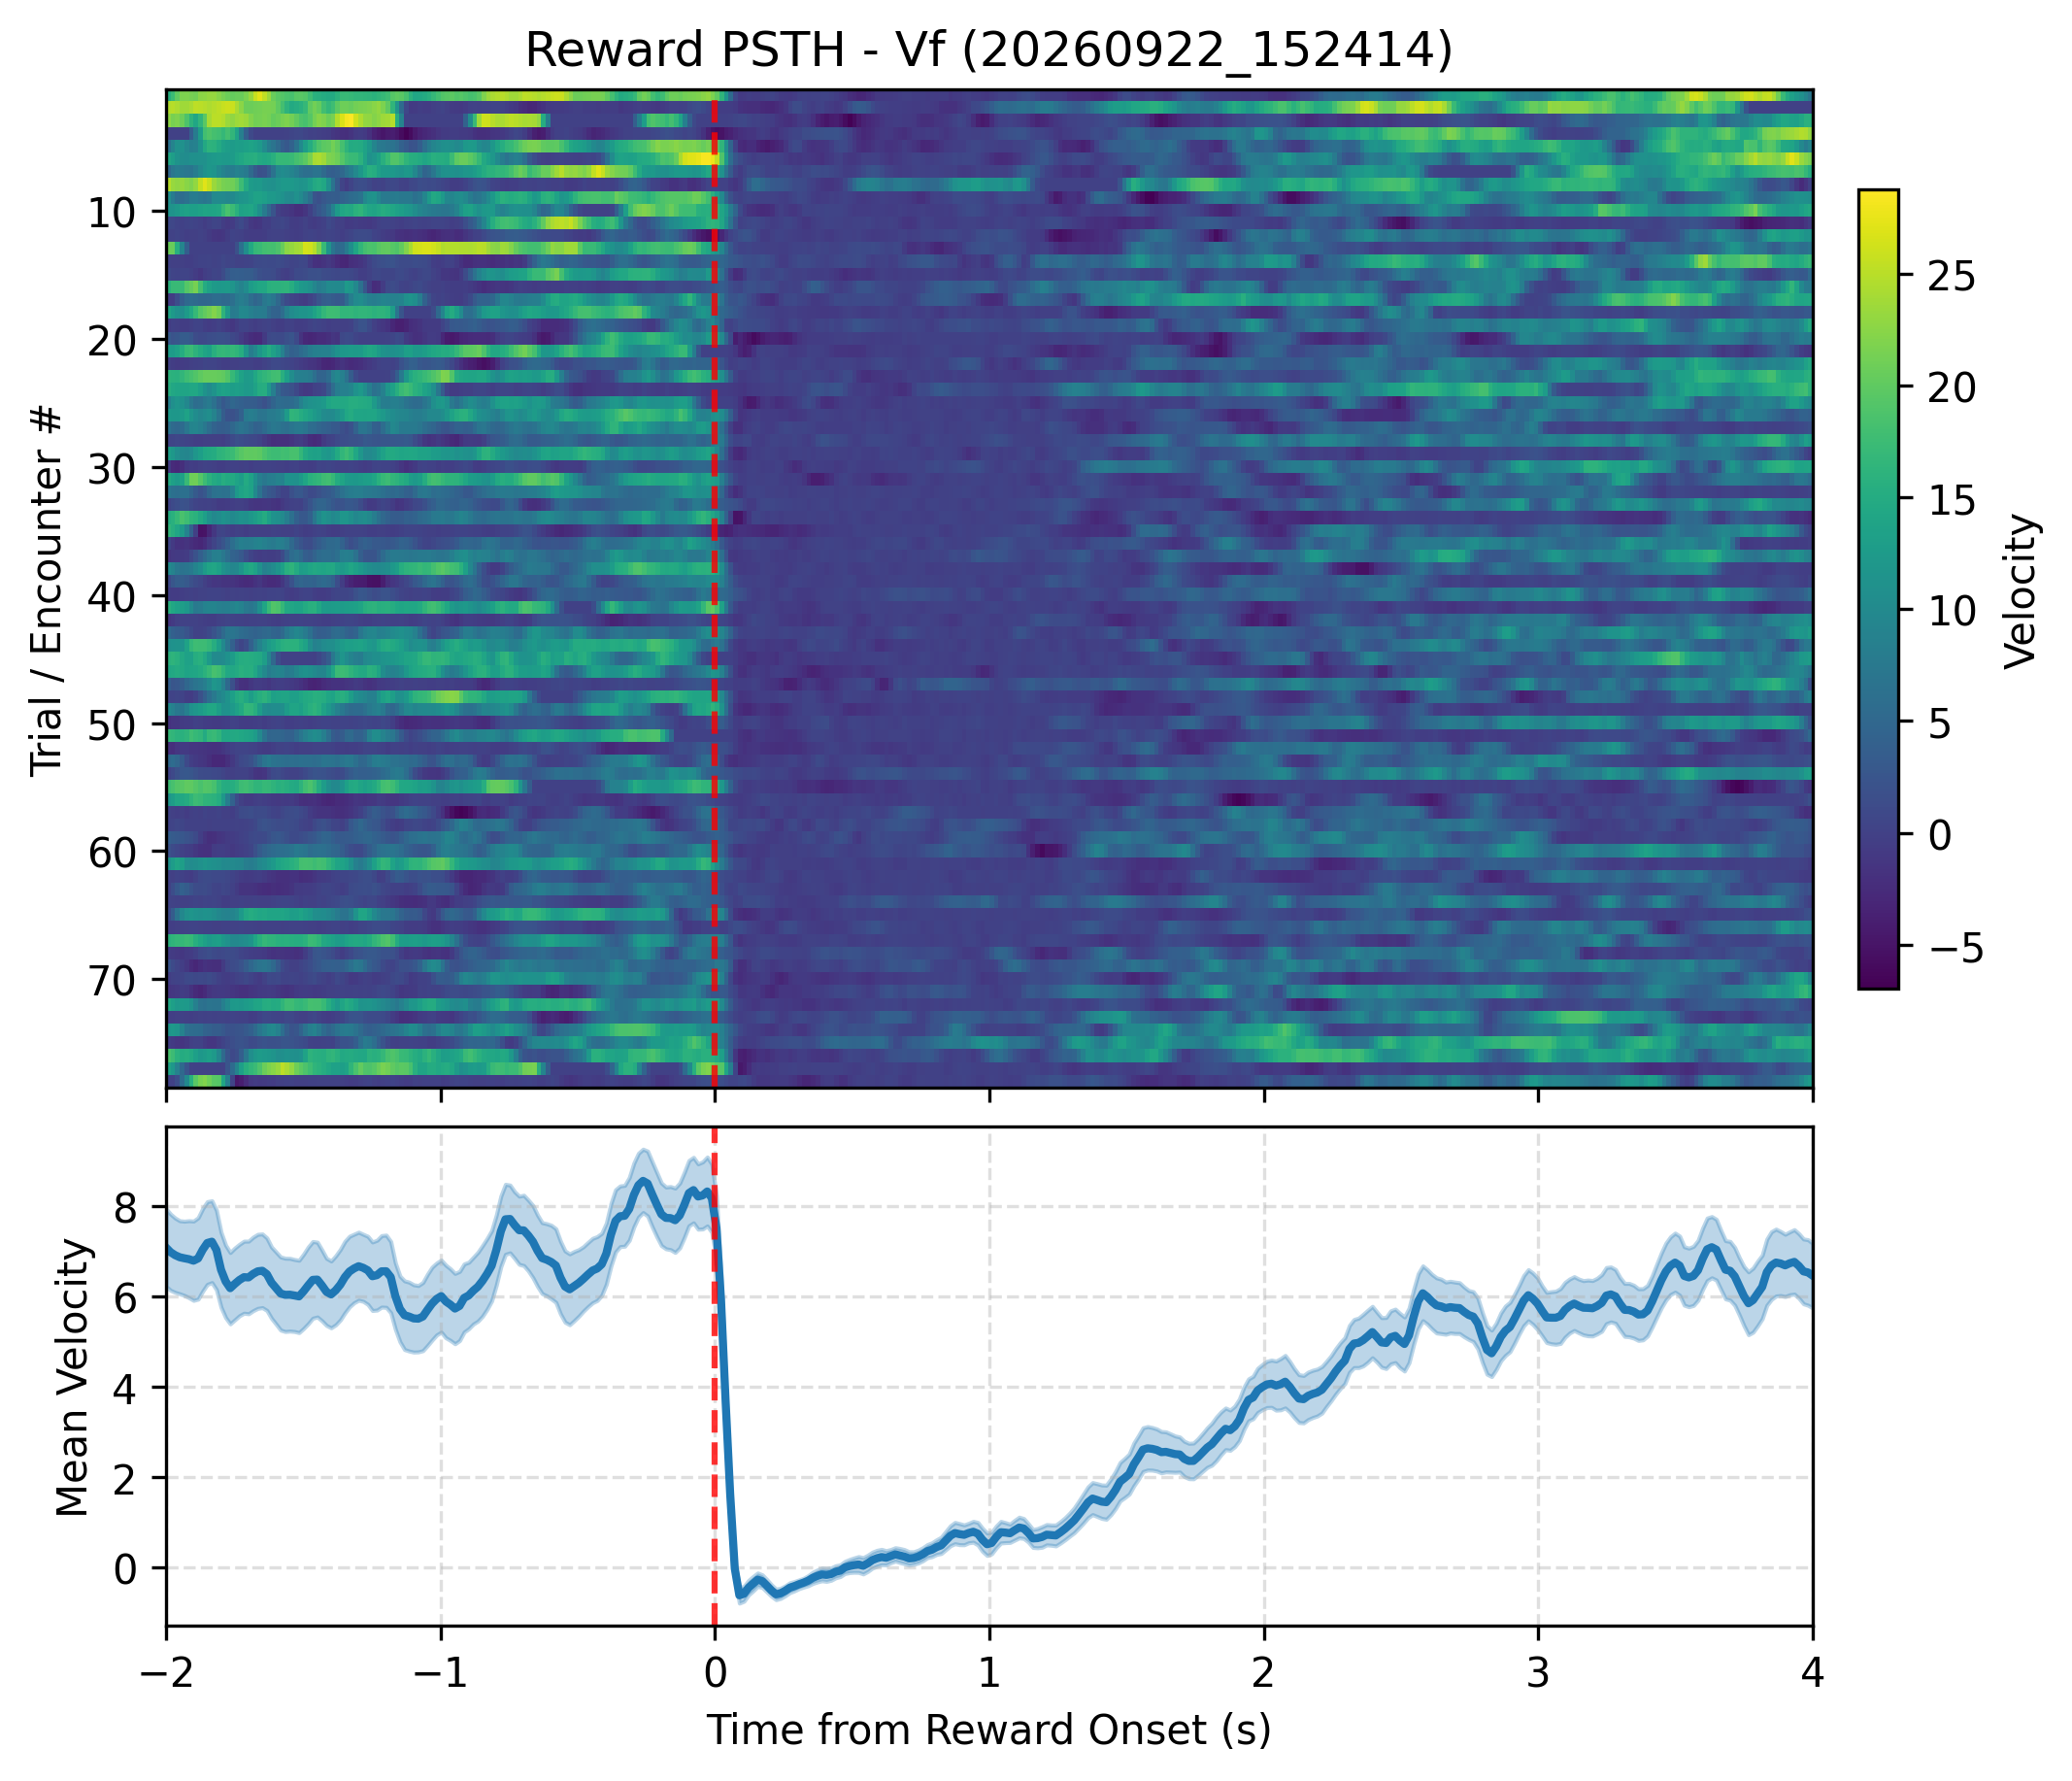

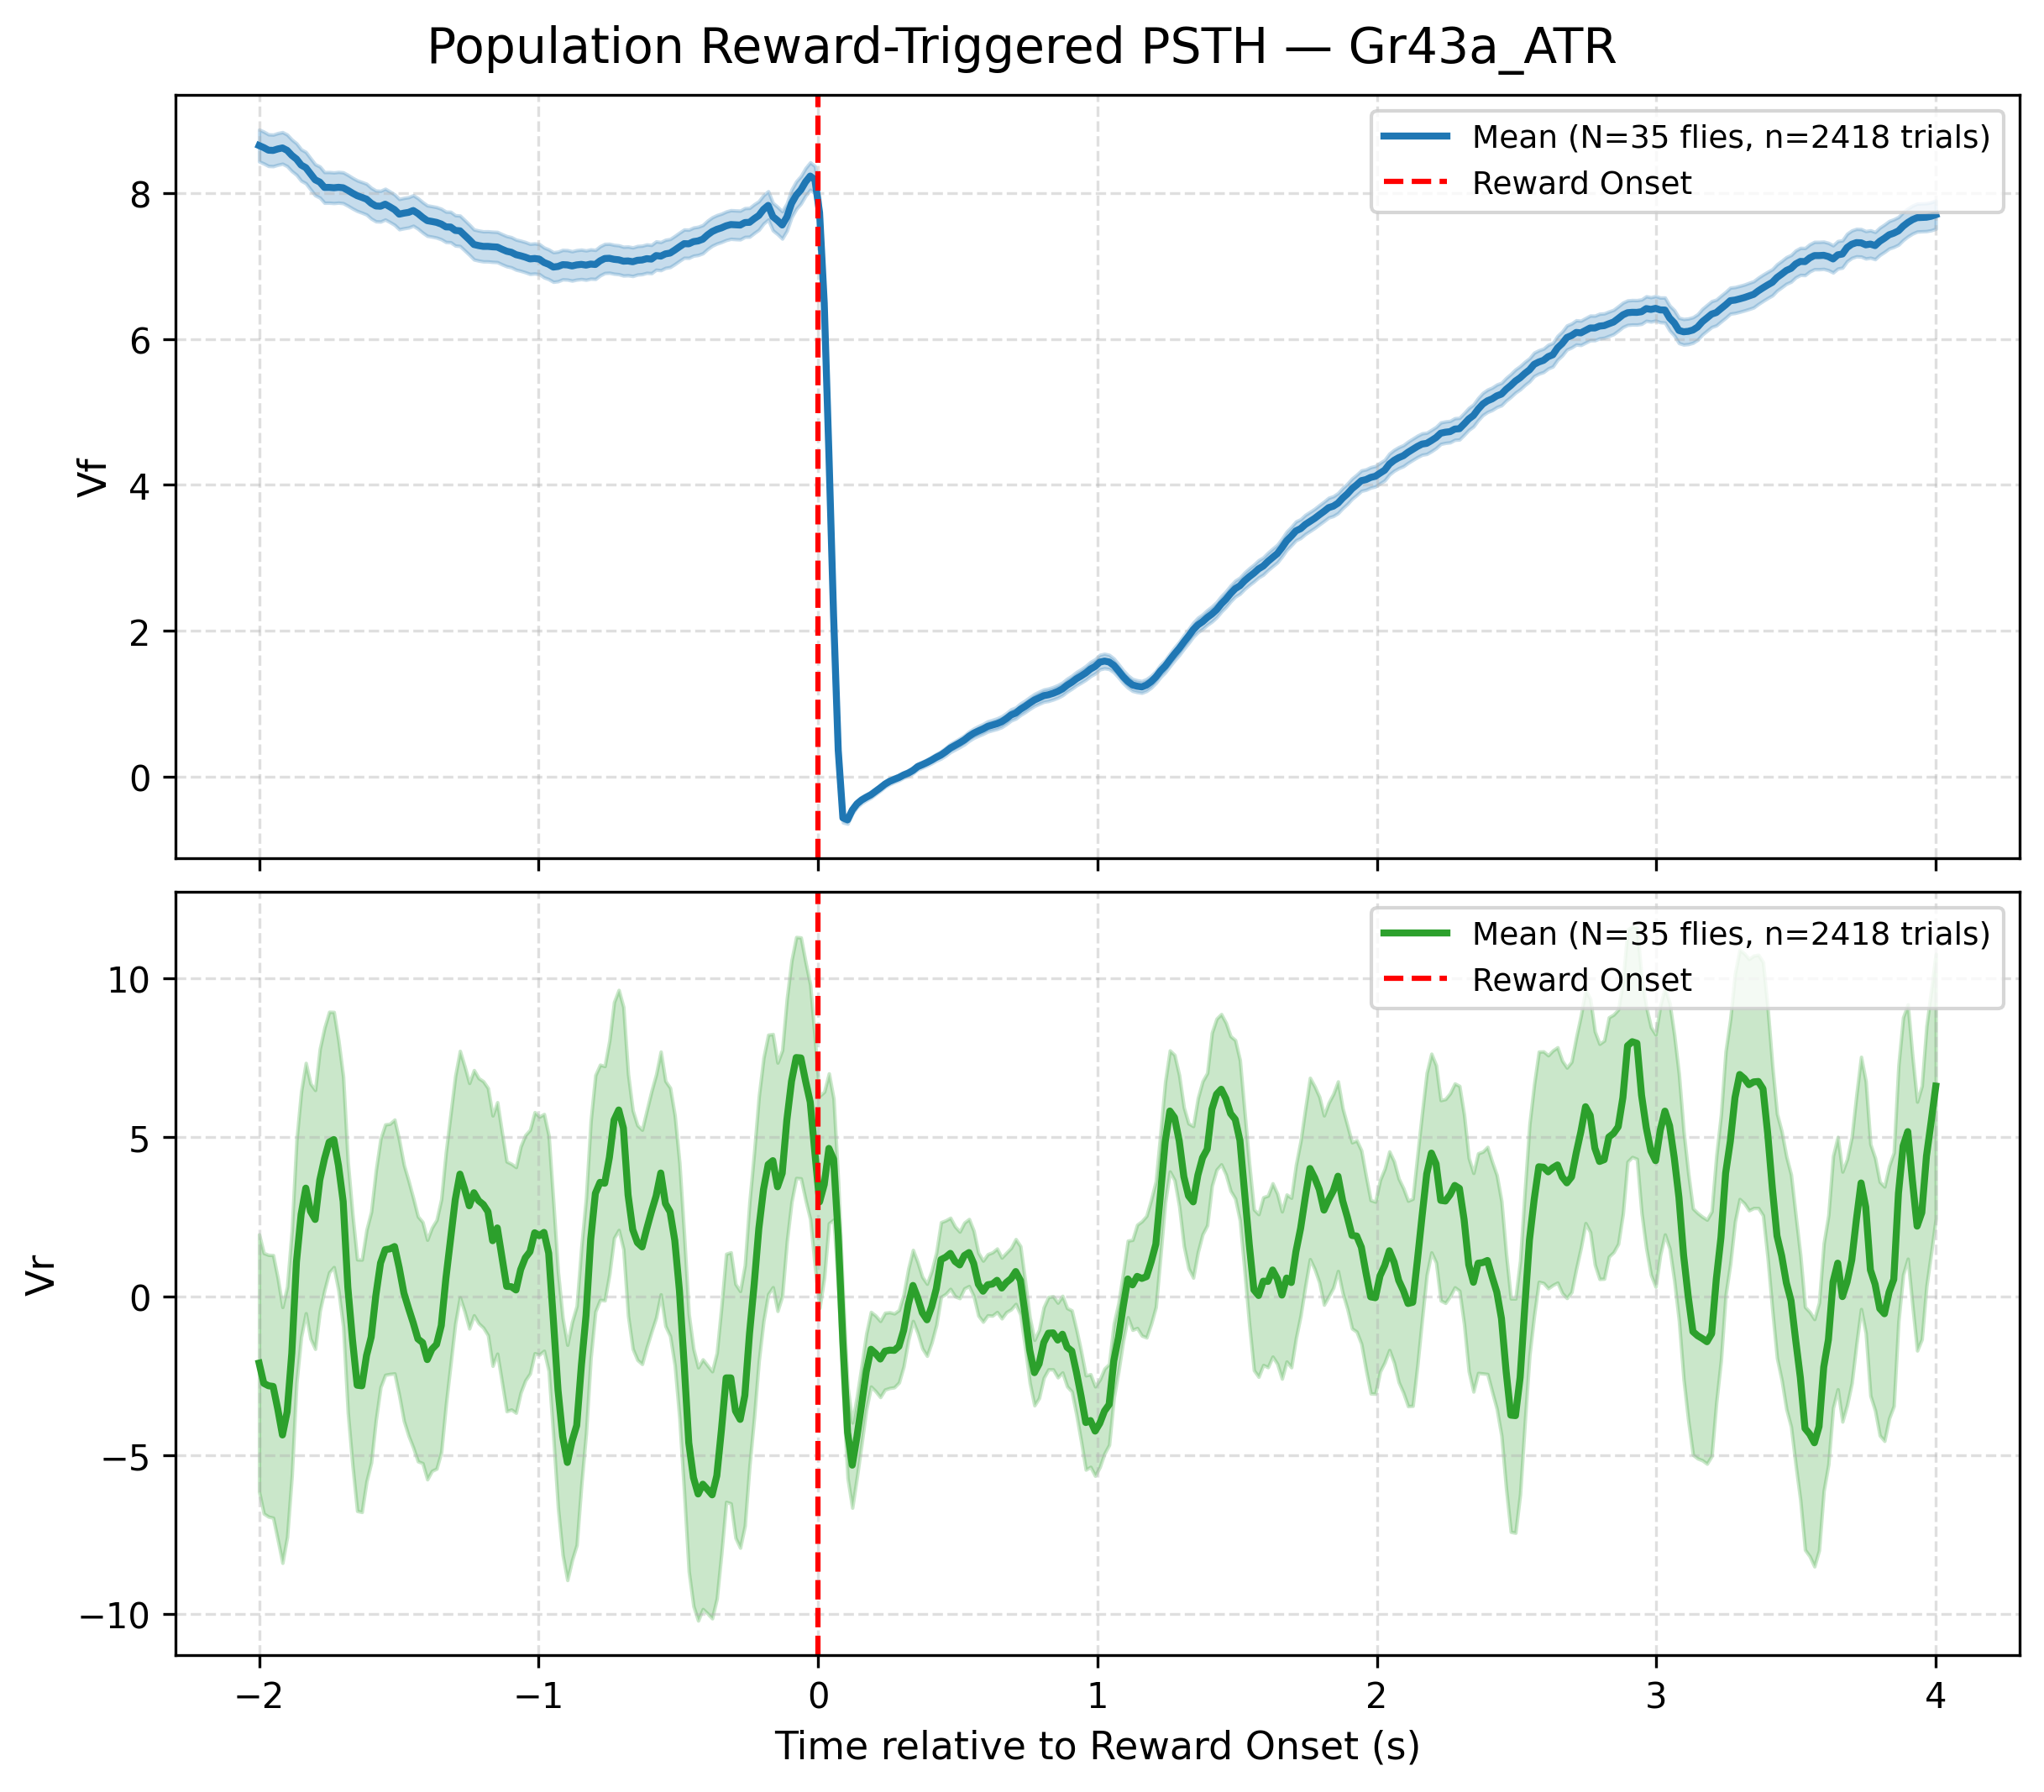

In [30]:
from behavior_fw.utils.psth import extract_experiment_psth
from behavior_fw.visualization.plot_psth import (
    plot_condition_psth_summary,
    plot_single_experiment_psth,
)

# 1. Option A: Plot Single Fly (Per Experiment)
exp = dataset[24]  # Pick fly 0
psth_dict = extract_experiment_psth(
    exp, metrics=["Vf_smooth", "Vr_smooth"], window_sec=(-2.0, 4.0)
)
fig_single, _ = plot_single_experiment_psth(
    psth_dict, metric="Vf_smooth", title=exp["uid"]
)
plt.show()

# 2. Option B: Plot Population PSTH (All Gr43a_ATR flies combined)
fig_cond, _ = plot_condition_psth_summary(
    dataset,
    condition_name="Gr43a_ATR",
    metrics=["Vf_smooth", "Vr_smooth"],
    window_sec=(-2.0, 4.0),
)
plt.show()

In [ ]:
# # 2. Load Protocol and Blocks Metadata
#         fpath_protocol = folder_path / "ProtocolMeta.csv"
#         df_protocol = get_protocol_params(fpath_protocol)

#         fpath_stim = folder_path / "stimulusLED.csv"
#         _, df_blocks = load_and_parse_led_stimulus(fpath_stim)

#         num_encounters = len(df_blocks)

#         if num_encounters > 0:
#             first_block = df_blocks.iloc[0]
#             first_encounter_row = df_merged[
#                 df_merged["LowResFrameNumber"] == first_block["onset_timetick"]
#             ]
#             first_frame_idx = (
#                 first_encounter_row.index[0]
#                 if not first_encounter_row.empty
#                 else None
#             )

#             last_block = df_blocks.iloc[-1]
#             last_offset_timetick = last_block.get("offset_timetick", None)

#             if last_offset_timetick is not None:
#                 last_offset_match = df_merged[
#                     df_merged["LowResFrameNumber"] == last_offset_timetick
#                 ]
#                 last_offset_row = (
#                     last_offset_match.index[0]
#                     if not last_offset_match.empty
#                     else None
#                 )
#             else:
#                 last_offset_row = None
#         else:
#             first_frame_idx = None
#             last_offset_row = None

#         # Build dictionary record
#         dataset.append(
#             {
#                 "file_index": i,
#                 "uid": uid,
#                 "df_track": df_merged,  # Now includes Vf_smooth, Vs_smooth, Vr_smooth, Vt_smooth!
#                 "zone_X": df_protocol["ZoneCenterX_mm"].iloc[0],
#                 "zone_Y": df_protocol["ZoneCenterY_mm"].iloc[0],
#                 "zone_r": df_protocol["ZoneRadius_mm"].iloc[0],
#                 "n_rewards": num_encounters,
#                 "first_reward_idx": first_frame_idx,
#                 "last_reward_idx": last_offset_row,
#             }
#         )


KeyError: 'traj_X'

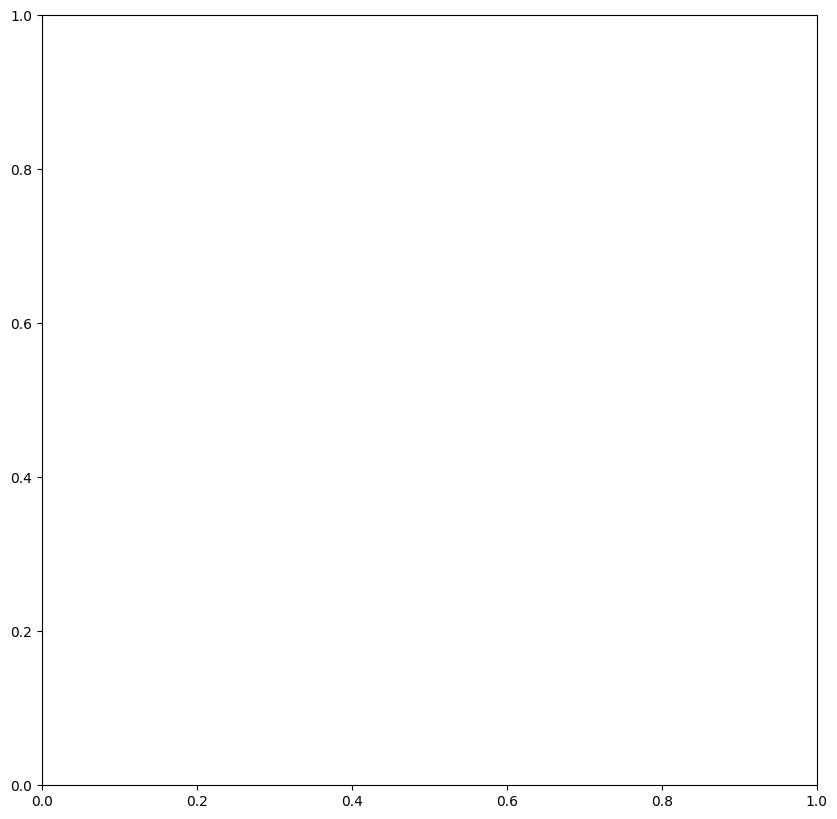

In [31]:
import matplotlib.patches as patches

for i, ds in enumerate(dataset):
    fig, ax = plt.subplots(1,1, figsize =(10,10))

    ax.plot(ds["traj_X"], ds["traj_Y"])
    if ds["first_reward_idx"]:
        idx_rw0 = ds["first_reward_idx"]
        idx_rw1 = ds["last_reward_idx"]
        ax.plot(ds["traj_X"][idx_rw0:idx_rw1], ds["traj_Y"][idx_rw0:idx_rw1])

    ax.set_xlim([-45.5, 45.5])
    ax.set_ylim([-45.5, 45.5])

    zone = patches.Circle((ds["zone_X"], ds["zone_Y"]), ds["zone_r"], alpha=1, fc=None, ec="red", fill=False, zorder=10, lw=2)
    ax.add_patch(zone)
    arena = patches.Circle((0, 0), 45, alpha=0.5, fc=None, ec="black", fill=False)
    ax.add_patch(arena)
    ax.set_aspect("equal")
    ax.axis("off")

    ax.set_title(f'{ds["uid"]} - {ds["n_rewards"]} rewards ; t0 = {idx_rw0/3600} min')



In [ ]:
# from pathlib import Path

# output_dir = Path("results/density_plots")
# output_dir.mkdir(parents=True, exist_ok=True)

# for file_idx in file_indices:
#     df_exp = df_all_traj[df_all_traj["file_index"] == file_idx].copy()
#     df_blocks_exp = df_all_blocks[df_all_blocks["file_index"] == file_idx]

#     epochs_dict = segment_experiment_epochs(df_exp, df_blocks_exp)

#     # Render Cartesian Plot
#     fig_cart, _ = plot_dynamic_epoch_densities(epochs_dict)
#     fig_cart.savefig(
#         output_dir / f"cartesian_density_file_{file_idx}.png",
#         dpi=300,
#         bbox_inches="tight",
#     )
#     plt.close(fig_cart)  # Prevents memory accumulation in notebook

#     # Render Polar Plot
#     fig_polar, _ = plot_dynamic_polar_densities(
#         epochs_dict, title_prefix=f"File {file_idx}"
#     )
#     fig_polar.savefig(
#         output_dir / f"polar_density_file_{file_idx}.png",
#         dpi=300,
#         bbox_inches="tight",
#     )
#     plt.close(fig_polar)

"""
- Closed-loop ATR (Active Drive): Contingent reward—evaluates how the fly modifies its local search dynamics, heading, and saccades when directly triggering neuronal activation.

- Open-loop / Replay ATR (Yoked Control): Decouples behavior from reinforcement—delivers the exact same temporal sequence of light pulses to test whether stimulus presence alone drives behavioral shifts, or if true spatial contingency (closed-loop) is required.

- No-Retinal / NR Control (Visual/Hardware Control): Controls for heat, light visual artifacts, or non-specific light avoidance without functional channelrhodopsin (Chrimson)."""

In [ ]:
# In your Jupyter Notebook:

import matplotlib.pyplot as plt
from behavior_fw.utils.epoch_aligner import segment_experiment_epochs
from behavior_fw.visualization.plot_density import (
    plot_dynamic_epoch_densities,
    plot_dynamic_polar_densities,
)

# Assume `df_all_traj` contains all tracking data and `df_all_blocks` contains reward metadata
file_indices = df_all_traj["file_index"].unique()

for file_idx in file_indices:
    print(f"\nProcessing Experiment File Index: {file_idx}")

    # 1. Filter tracking and block data for current experiment
    df_exp = df_all_traj[df_all_traj["file_index"] == file_idx].copy()

    # Get block data if available for this file
    if "file_index" in df_all_blocks.columns:
        df_blocks_exp = df_all_blocks[
            df_all_blocks["file_index"] == file_idx
        ].copy()
    else:
        df_blocks_exp = df_all_blocks

    # 2. Extract Reward Zone parameters (if defined in metadata/DataFrame)
    reward_zone = {
        "x_mm": df_exp["zone_x_mm"].iloc[0]
        if "zone_x_mm" in df_exp.columns
        else 0,
        "y_mm": df_exp["zone_y_mm"].iloc[0]
        if "zone_y_mm" in df_exp.columns
        else 0,
        "radius_mm": df_exp["zone_r_mm"].iloc[0]
        if "zone_r_mm" in df_exp.columns
        else 10,
    }

    # 3. Automatically segment into Baseline, Active Reward, and Extinction Epochs
    epochs_dict = segment_experiment_epochs(df_exp, df_blocks_exp)

    # 4. Plot Cartesian Density
    fig_cart, axes_cart = plot_dynamic_epoch_densities(
        epochs_dict=epochs_dict, reward_zone_mm=reward_zone, arena_r=45.0
    )
    fig_cart.suptitle(
        f"Cartesian Density - File {file_idx}", fontsize=14, y=1.05
    )
    plt.show()

    # 5. Plot Polar Density
    fig_polar, axes_polar = plot_dynamic_polar_densities(
        epochs_dict=epochs_dict, arena_r=45.0, title_prefix=f"File {file_idx}"
    )
    plt.show()

In [ ]:
# # behavior_fw/analysis/epoch_aligner.py

# from pathlib import Path
# import numpy as np
# import pandas as pd


# def load_and_parse_led_stimulus(
#     stim_csv_path: str | Path,
# ) -> tuple[pd.DataFrame, pd.DataFrame]:
#     """Reads the 3-column LED stimulus CSV and extracts discrete reward block events.

#     Columns:
#     0: Frame Index
#     1: Low-res timetick
#     2: LED State (0 or 1)
#     """
#     stim_csv_path = Path(stim_csv_path)

#     # 1. Load CSV (no header)
#     df_stim = pd.read_csv(
#         stim_csv_path,
#         header=0
#     )

#     # Ensure led_state is integer (0 or 1)
#     df_stim["LEDstate"] = df_stim["LEDstate"].astype(int)

#     # 2. Detect transitions (diff = +1 for ON, -1 for OFF)
#     led_diff = np.diff(df_stim["LEDstate"].values, prepend=0)

#     # Onset indices where LED flips from 0 -> 1
#     onset_mask = led_diff == 1
#     offset_mask = led_diff == -1

#     onset_df = df_stim[onset_mask].copy().reset_index(drop=True)
#     offset_df = df_stim[offset_mask].copy().reset_index(drop=True)

#     # Build summary of discrete reward blocks
#     reward_blocks = []
#     for i in range(len(onset_df)):
#         block_info = {
#             "encounter_id": i + 1,
#             "onset_frame_stim": onset_df.loc[i, "Index"],
#             "onset_timetick": onset_df.loc[i, "LowResFrameNumber"],
#         }
#         if i < len(offset_df):
#             block_info["offset_frame_stim"] = offset_df.loc[i, "Index"]
#             block_info["offset_timetick"] = offset_df.loc[i, "LowResFrameNumber"]

#         reward_blocks.append(block_info)

#     df_blocks = pd.DataFrame(reward_blocks)

#     return df_stim, df_blocks

In [ ]:
# 1. Load raw tracking data
df_tracking = pd.read_csv(fpath_track)

# 2. Parse stimulus CSV
fpath_stim = Path(row["folder_path"]) / "stimulusLED.csv"
df_stim, df_blocks = load_and_parse_led_stimulus(fpath_stim)

# 3. Merge tracking data with LED status via shared timetick
df_merged = pd.merge(
    df_tracking,
    df_stim[["LowResFrameNumber", "LEDstate"]],
    on="LowResFrameNumber",
    how="left",
)
df_merged["LEDstate"] = df_merged["LEDstate"].fillna(0).astype(int)

# -------------------------------------------------------------
# ANSWERING YOUR 2 QUESTIONS
# -------------------------------------------------------------

# 1. Number of reward encounters (discrete blocks)
num_encounters = len(df_blocks)

print(f"Total Reward Encounters: {num_encounters}")

# 2. First reward encounter moment
if num_encounters > 0:
    first_block = df_blocks.iloc[0]

    # Find the corresponding row index/time in your tracking DataFrame
    first_encounter_row = df_merged[
        df_merged["LowResFrameNumber"] == first_block["onset_timetick"]
    ]

    first_frame_idx = first_encounter_row.index[0]
    first_timetick = first_block["onset_timetick"]

    print("\n--- First Reward Encounter ---")
    print(f"Encounter ID: 1")
    print(f"Onset Timetick: {first_timetick}")
    print(f"Tracking Frame Row Index: {first_frame_idx}")

    # If your tracking frame rate is known (e.g. 30 fps or timestamp in seconds):
    if "time_sec" in df_merged.columns:
        print(f"Time in Trial: {df_merged.loc[first_frame_idx, 'time_sec']:.2f} seconds")
else:
    print("No reward encounters detected in this file.")